NameError: name 'os' is not defined

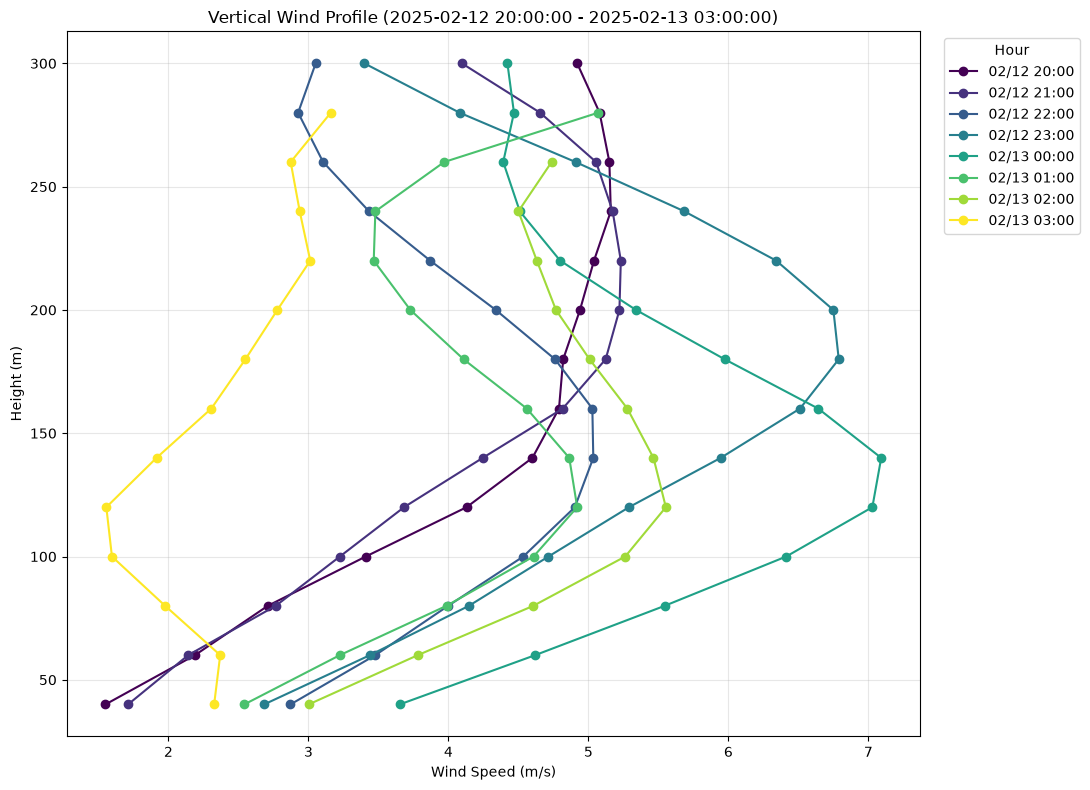

In [1]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# 0. データの読み込み
# ============================================================
df = pd.read_pickle("Sample_Feb.pkl")

# ============================================================
# 設定: 開始時刻・終了時刻・出力先
# ============================================================
START_TIME = "2025-02-12 20:00:00"
END_TIME = "2025-02-13 03:00:00"

# 高度レンジ (40m~300mを20mごと)
HEIGHTS = list(range(40, 301, 20))

# 保存先パス (必要に応じて変更してください)
OUTPUT_PATH = "wind_profile.png"

# ------------------------------------------------------------
# 1. タイムスタンプをdatetime型に変換
# ------------------------------------------------------------
df = df.copy()
df["Timestamp (end of interval)"] = pd.to_datetime(
    df["Timestamp (end of interval)"]
)

# ------------------------------------------------------------
# 2. 指定した期間だけ抽出
# ------------------------------------------------------------
mask = (df["Timestamp (end of interval)"] >= pd.to_datetime(START_TIME)) & (
    df["Timestamp (end of interval)"] <= pd.to_datetime(END_TIME)
)
df_period = df.loc[mask].copy()

# ------------------------------------------------------------
# 3. 1時間ごとにグループ化するためのラベルを作成
#    (00:10~01:00 なら "01:00" 側の時間に属する切り方)
# ------------------------------------------------------------
df_period["Hour Group"] = df_period[
    "Timestamp (end of interval)"
].dt.floor("h") + pd.to_timedelta(
    (df_period["Timestamp (end of interval)"].dt.minute != 0) * 1, unit="h"
)

# 対象の風速カラム名
wind_cols = [f"{h}m Wind Speed (m/s)" for h in HEIGHTS]

# ------------------------------------------------------------
# 4. 1時間ごとの平均を計算
# ------------------------------------------------------------
hourly_mean = df_period.groupby("Hour Group")[wind_cols].mean()

# ------------------------------------------------------------
# 5. プロット
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 8))

colors = cm.viridis(np.linspace(0, 1, len(hourly_mean)))

for color, (hour_label, row) in zip(colors, hourly_mean.iterrows()):
  ax.plot(
      row.values,
      HEIGHTS,
      marker="o",
      color=color,
      label=hour_label.strftime("%m/%d %H:%M"),
  )

ax.set_xlabel("Wind Speed (m/s)")
ax.set_ylabel("Height (m)")
ax.set_title(f"Vertical Wind Profile ({START_TIME} - {END_TIME})")
ax.legend(title="Hour", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)

plt.tight_layout()

# 出力先ディレクトリが存在しない場合は自動作成して保存
output_dir = os.path.dirname(OUTPUT_PATH)
if output_dir:
  os.makedirs(output_dir, exist_ok=True)

plt.savefig(OUTPUT_PATH, dpi=150)
plt.show()